# Coffee Matchmaker — Coffee Profiles (Clustering)

The app has a path for people who don't know much about coffee: instead of typing a request, they pick a **coffee profile** like "fruity and floral" or "chocolate and nuts", and get coffees from it.

Nobody labeled these profiles, so this is **unsupervised learning**: I let clustering find groups of coffees that taste alike, then name each group from what's in it.

**Input:** `data/coffee_enriched.csv` from the modeling notebook.
**Output:** a `profile_id` for every coffee, and `data/profiles.json` with each profile's name and description for the app.

## 1. Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 2. Load the Data and Choose the Taste Features

A profile should describe **how a coffee tastes**, so I cluster only on taste:

- The six **flavor families** (0 or 1): fruity, citrus, floral, chocolate, nutty, caramel/sweet.
- The three **taste scores** from the modeling notebook (0 to 1): acidity, body, bitterness.

I leave out origin, process and price on purpose. Two coffees from different countries can taste the same, and a beginner picks by taste, not by country.

All nine features are already between 0 and 1, so they are on the same scale and I don't need a scaler.

In [2]:
df = pd.read_csv("../data/coffee_enriched.csv", encoding="utf-8-sig")

flavors = ["note_fruity", "note_citrus", "note_floral", "note_chocolate", "note_nutty", "note_caramel_sweet"]
scores = ["acidity_score", "body_score", "bitterness_score"]
features = flavors + scores

X = df[features]
print("Coffees:", X.shape[0], "| Features:", X.shape[1])
print()
print(X.describe().round(2).loc[["mean", "min", "max"]])

Coffees: 569 | Features: 9

      note_fruity  note_citrus  note_floral  note_chocolate  note_nutty  note_caramel_sweet  acidity_score  body_score  bitterness_score
mean         0.73         0.16          0.2            0.42        0.25                0.35            0.5         0.5               0.5
min          0.00         0.00          0.0            0.00        0.00                0.00            0.0         0.0               0.0
max          1.00         1.00          1.0            1.00        1.00                1.00            1.0         1.0               1.0


## 3. How Many Profiles? Comparing K-Means and Agglomerative Clustering

I try 2 to 8 clusters with two algorithms and measure each with the **Silhouette score**: for every coffee, how close it is to its own cluster compared with the nearest other cluster. It goes from −1 to 1, and higher means clearer, better-separated clusters.

   K-Means  Agglomerative
k                        
2    0.301          0.275
3    0.287          0.222
4    0.302          0.253
5    0.327          0.280
6    0.345          0.285
7    0.361          0.328
8    0.378          0.342


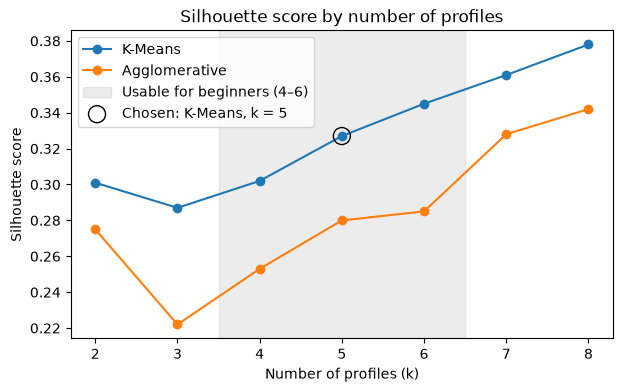

In [3]:
results = []
for k in range(2, 9):
    kmeans_labels = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X)
    agglo_labels = AgglomerativeClustering(n_clusters=k).fit_predict(X)
    results.append({"k": k,
                    "K-Means": round(silhouette_score(X, kmeans_labels), 3),
                    "Agglomerative": round(silhouette_score(X, agglo_labels), 3)})

results = pd.DataFrame(results).set_index("k")
print(results)

plt.figure(figsize=(7, 4))
plt.plot(results.index, results["K-Means"], marker="o", label="K-Means")
plt.plot(results.index, results["Agglomerative"], marker="o", label="Agglomerative")
plt.axvspan(3.5, 6.5, color="gray", alpha=0.15, label="Usable for beginners (4–6)")
plt.scatter([5], [results.loc[5, "K-Means"]], s=150, facecolors="none", edgecolors="black", zorder=3, label="Chosen: K-Means, k = 5")
plt.xlabel("Number of profiles (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score by number of profiles")
plt.legend()
plt.show()

**Reading the results:**

- **K-Means beats Agglomerative at every k**, so I use K-Means.
- The silhouette keeps rising as k grows. That's expected with yes/no flavor flags: with more clusters, each one can hold an exact combination of flags. So the silhouette alone can't pick k here, and I add a practical limit: a beginner should choose from **4 to 6** profiles. More than that is as confusing as the coffee list itself.
- Inside that range, I compared **5 and 6** in detail (next cell). With 6, the "chocolate and nuts" group splits into two groups that taste almost the same, which would confuse users for a small gain in silhouette (0.345 vs 0.327). **5 profiles** are all clearly different, so I choose **k = 5**.

In [4]:
for k in [5, 6]:
    labels = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X)
    print("k =", k)
    print(X.groupby(labels).mean().round(2).assign(coffees=pd.Series(labels).value_counts()))
    print()

k = 5
   note_fruity  note_citrus  note_floral  note_chocolate  note_nutty  note_caramel_sweet  acidity_score  body_score  bitterness_score  coffees
0         0.91         0.23         1.00            0.05        0.03                0.22           0.80        0.17              0.21       88
1         0.98         0.17         0.08            1.00        0.15                0.20           0.39        0.71              0.66      122
2         0.07         0.09         0.10            0.83        0.76                0.57           0.19        0.80              0.79      133
3         0.87         0.17         0.01            0.00        0.10                1.00           0.62        0.37              0.35       78
4         0.94         0.16         0.00            0.00        0.10                0.00           0.64        0.33              0.37      148

k = 6
   note_fruity  note_citrus  note_floral  note_chocolate  note_nutty  note_caramel_sweet  acidity_score  body_score  bitterness_s

## 4. Fit the Final Model (k = 5)

In [5]:
kmeans = KMeans(n_clusters=5, n_init=20, random_state=42)
df["cluster"] = kmeans.fit_predict(X)

profile_means = df.groupby("cluster")[features].mean().round(2)
profile_means["coffees"] = df["cluster"].value_counts()
print(profile_means)

         note_fruity  note_citrus  note_floral  note_chocolate  note_nutty  note_caramel_sweet  acidity_score  body_score  bitterness_score  coffees
cluster                                                                                                                                             
0               0.91         0.23         1.00            0.05        0.03                0.22           0.80        0.17              0.21       88
1               0.98         0.17         0.08            1.00        0.15                0.20           0.39        0.71              0.66      122
2               0.07         0.09         0.10            0.83        0.76                0.57           0.19        0.80              0.79      133
3               0.87         0.17         0.01            0.00        0.10                1.00           0.62        0.37              0.35       78
4               0.94         0.16         0.00            0.00        0.10                0.00           0

In [6]:
def top_notes(rows, n=6):
    notes = rows["tasting_notes"][rows["tasting_notes"] != "Unknown"].str.split("; ").explode()
    return notes.value_counts().head(n).index.tolist()

for c in sorted(df["cluster"].unique()):
    rows = df[df["cluster"] == c]
    print("Cluster", c, "|", len(rows), "coffees")
    print("   Most common notes:", top_notes(rows))
    print("   Main origins:     ", rows["origin_country"].value_counts().head(3).to_dict())
    print()

Cluster 0 | 88 coffees
   Most common notes: ['Floral', 'Jasmine', 'Peach', 'Strawberry', 'Berries', 'Orange']
   Main origins:      {'Ethiopia': 52, 'Colombia': 19, 'Costa Rica': 3}

Cluster 1 | 122 coffees
   Most common notes: ['Chocolate', 'Dark chocolate', 'Cocoa', 'Grape', 'Strawberry', 'Berries']
   Main origins:      {'Colombia': 27, 'Ethiopia': 25, 'Uganda': 13}

Cluster 2 | 133 coffees
   Most common notes: ['Chocolate', 'Caramel', 'Nuts', 'Hazelnut', 'Brown sugar', 'Dark chocolate']
   Main origins:      {'Multiple': 42, 'Brazil': 39, 'Colombia': 24}

Cluster 3 | 78 coffees
   Most common notes: ['Caramel', 'Vanilla', 'Brown sugar', 'Strawberry', 'Grape', 'Peach']
   Main origins:      {'Colombia': 28, 'Ethiopia': 16, 'Costa Rica': 5}

Cluster 4 | 148 coffees
   Most common notes: ['Strawberry', 'Berries', 'Peach', 'Tropical fruits', 'Pineapple', 'Grape']
   Main origins:      {'Colombia': 53, 'Ethiopia': 33, 'Yemen': 10}



## 5. Name the Profiles

K-Means numbers clusters in a random order, so I don't name them by number. I name each one from **what its center looks like**, with simple rules. This way the names stay correct even if the numbers change when someone reruns the notebook:

| Rule (checked in this order) | Profile |
|---|---|
| Mostly floral | Floral & bright |
| Mostly **not** fruity | Chocolate & nuts |
| Fruity and chocolate | Fruity & chocolatey |
| Fruity and caramel/sweet | Fruity & sweet |
| Fruity, nothing else | Juicy & fruity |

In [7]:
profile_info = {
    "floral_bright": {"order": 0,
        "name": {"ar": "زهري ومشرق", "en": "Floral & bright"},
        "description": {"ar": "ياسمين وزهور وفواكه، حموضة واضحة وقوام خفيف",
                        "en": "Jasmine, flowers and fruit, with bright acidity and a light body"}},
    "juicy_fruity": {"order": 1,
        "name": {"ar": "فواكه وتوت", "en": "Juicy & fruity"},
        "description": {"ar": "فراولة وتوت وفواكه استوائية، منعش وحموضته متوسطة لعالية",
                        "en": "Strawberry, berries and tropical fruit, refreshing with medium-high acidity"}},
    "fruity_sweet": {"order": 2,
        "name": {"ar": "فواكه وحلاوة", "en": "Fruity & sweet"},
        "description": {"ar": "فواكه مع كراميل وفانيلا وسكر بني، متوازن وحلو",
                        "en": "Fruit with caramel, vanilla and brown sugar, sweet and balanced"}},
    "fruity_chocolate": {"order": 3,
        "name": {"ar": "فواكه وشوكولاتة", "en": "Fruity & chocolatey"},
        "description": {"ar": "شوكولاتة مع توت وعنب، قوام متوسط لثقيل",
                        "en": "Chocolate with berries and grape, medium to full body"}},
    "chocolate_nuts": {"order": 4,
        "name": {"ar": "شوكولاتة ومكسرات", "en": "Chocolate & nuts"},
        "description": {"ar": "شوكولاتة ومكسرات وكراميل، حموضة خفيفة وقوام ثقيل ومرارة أعلى",
                        "en": "Chocolate, nuts and caramel, with low acidity, full body and more bitterness"}},
}

def name_cluster(center):
    if center["note_floral"] >= 0.5:
        return "floral_bright"
    if center["note_fruity"] < 0.5:
        return "chocolate_nuts"
    if center["note_chocolate"] >= 0.5:
        return "fruity_chocolate"
    if center["note_caramel_sweet"] >= 0.5:
        return "fruity_sweet"
    return "juicy_fruity"

cluster_to_key = {c: name_cluster(profile_means.loc[c]) for c in profile_means.index}
print(cluster_to_key)
print("Every profile name used exactly once:", sorted(cluster_to_key.values()) == sorted(profile_info.keys()))

df["profile_key"] = df["cluster"].map(cluster_to_key)
df["profile_id"] = df["profile_key"].map(lambda key: profile_info[key]["order"])
print()
print(df.groupby(["profile_id", "profile_key"]).size().rename("coffees"))

{0: 'floral_bright', 1: 'fruity_chocolate', 2: 'chocolate_nuts', 3: 'fruity_sweet', 4: 'juicy_fruity'}
Every profile name used exactly once: True

profile_id  profile_key     
0           floral_bright        88
1           juicy_fruity        148
2           fruity_sweet         78
3           fruity_chocolate    122
4           chocolate_nuts      133
Name: coffees, dtype: int64


## 6. A Picture of the Profiles (PCA)

The coffees live in 9 dimensions, so I use **PCA** to squeeze them into 2 just for drawing (it keeps about 56% of the information, so some groups overlap in the picture even though they're separate in 9D). Each dot is a coffee, colored by its profile. PCA is only for this picture. The clustering itself used all 9 features.

Share of the information kept in 2D: 56 %


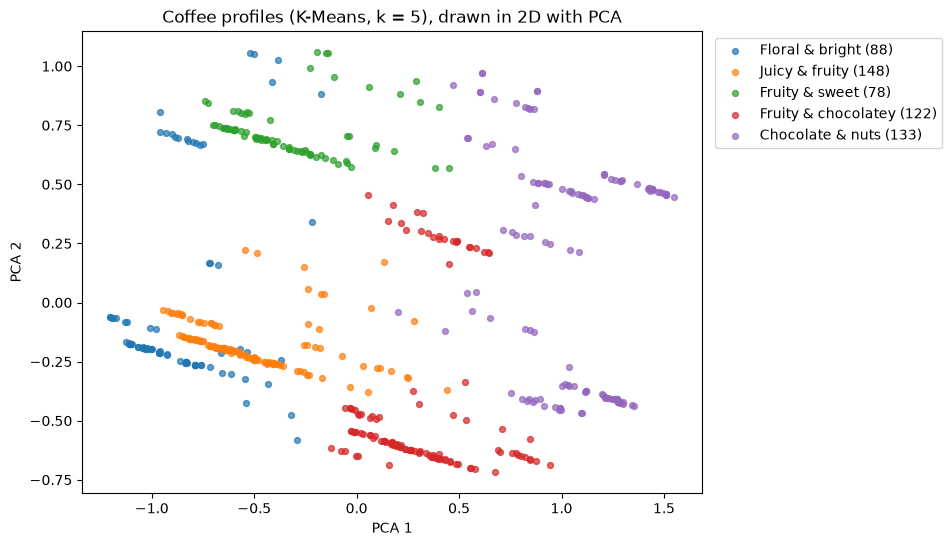

In [8]:
pca = PCA(n_components=2, random_state=42)
points = pca.fit_transform(X)
print("Share of the information kept in 2D:", round(pca.explained_variance_ratio_.sum() * 100), "%")

plt.figure(figsize=(8, 6))
for key, info in sorted(profile_info.items(), key=lambda item: item[1]["order"]):
    mask = df["profile_key"] == key
    plt.scatter(points[mask, 0], points[mask, 1], s=18, alpha=0.7, label=info["name"]["en"] + f" ({mask.sum()})")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Coffee profiles (K-Means, k = 5), drawn in 2D with PCA")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

## 7. Save

In [9]:
df.drop(columns=["cluster", "profile_key"]).to_csv("../data/coffee_enriched.csv", index=False, encoding="utf-8-sig")
print("Added profile_id to data/coffee_enriched.csv")

profiles = []
for key, info in sorted(profile_info.items(), key=lambda item: item[1]["order"]):
    rows = df[df["profile_key"] == key]
    profiles.append({
        "profile_id": info["order"],
        "key": key,
        "name": info["name"],
        "description": info["description"],
        "top_notes": top_notes(rows, 4),
        "n_coffees": int(len(rows)),
    })

with open("../data/profiles.json", "w", encoding="utf-8") as f:
    json.dump(profiles, f, ensure_ascii=False, indent=2)

print("Saved data/profiles.json")
for p in profiles:
    print(p["profile_id"], p["name"]["en"], "|", p["n_coffees"], "coffees |", p["top_notes"])

Added profile_id to data/coffee_enriched.csv
Saved data/profiles.json
0 Floral & bright | 88 coffees | ['Floral', 'Jasmine', 'Peach', 'Strawberry']
1 Juicy & fruity | 148 coffees | ['Strawberry', 'Berries', 'Peach', 'Tropical fruits']
2 Fruity & sweet | 78 coffees | ['Caramel', 'Vanilla', 'Brown sugar', 'Strawberry']
3 Fruity & chocolatey | 122 coffees | ['Chocolate', 'Dark chocolate', 'Cocoa', 'Grape']
4 Chocolate & nuts | 133 coffees | ['Chocolate', 'Caramel', 'Nuts', 'Hazelnut']


## Summary

- **Method:** K-Means on 9 taste features (6 flavor families + acidity, body and bitterness scores).
- **Model selection:** K-Means beat Agglomerative Clustering on silhouette at every k. I chose k = 5: within the 4–6 range that works for beginners, it gives five clearly different profiles, while k = 6 splits one profile into two near-identical ones.
- **For the app:** `recommend_by_profile(profile_id)` returns coffees with that `profile_id`, and `/profiles` reads `data/profiles.json`.